In [3]:
# STEP 1: IMPORT REQUIRED LIBRARIES & SET UP ENVIRONMENT
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Preprocessing & Model Selection
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

# Regression Algorithms & Metrics
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Classification Algorithms & Metrics
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    confusion_matrix, classification_report, precision_recall_curve
)

# Plot Aesthetic Configuration
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"
print("All required libraries imported successfully!")


All required libraries imported successfully!


In [4]:
# STEP 2: DATA LOADING & SYNTHETIC FALLBACK INGESTION
file_path = 'DataCoSupplyChainDataset.csv'

try:
    df = pd.read_csv(file_path, encoding='ISO-8859-1')
    print(f"Loaded dataset '{file_path}' successfully! Shape: {df.shape}")
except FileNotFoundError:
    print(f"File '{file_path}' not found. Generating demonstration dataset (N=5000)...")
    np.random.seed(42)
    n_samples = 5000
    df = pd.DataFrame({
        'Days for shipping (real)': np.random.randint(1, 7, n_samples),
        'Days for shipment (scheduled)': np.random.randint(1, 5, n_samples),
        'Late_delivery_risk': np.random.choice([0, 1], p=[0.45, 0.55], size=n_samples),
        'Shipping Mode': np.random.choice(['Standard Class', 'Second Class', 'First Class', 'Same Day'], size=n_samples),
        'Order Status': np.random.choice(['COMPLETE', 'PENDING', 'CLOSED'], size=n_samples),
        'Market': np.random.choice(['LATAM', 'Europe', 'Pacific Asia', 'USCA', 'Africa'], size=n_samples),
        'Order Region': np.random.choice(['Central America', 'Western Europe', 'South America'], size=n_samples),
        'Order Item Quantity': np.random.randint(1, 6, n_samples),
        'Sales per customer': np.random.uniform(20.0, 500.0, n_samples),
        'Latitude': np.random.uniform(-30.0, 50.0, n_samples),
        'Longitude': np.random.uniform(-100.0, 140.0, n_samples),
        'order date (DateOrders)': pd.date_range(start='2015-01-01', periods=n_samples, freq='h')
    })
    print(f"Created synthetic dataset with shape: {df.shape}")


Loaded dataset 'DataCoSupplyChainDataset.csv' successfully! Shape: (180519, 53)


In [5]:
# STEP 3: DATA AUDIT & SUMMARY STATISTICS
print("--- Dataset Head (First 5 Rows) ---")
print(df.head())

print("\n--- Summary Statistics of Targets & Numerical Predictors ---")
num_cols = ['Days for shipping (real)', 'Days for shipment (scheduled)', 'Sales per customer', 'Order Item Quantity']
print(df[[c for c in num_cols if c in df.columns]].describe().round(2))

print("\n--- Missing Values Audit ---")
missing_df = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
missing_audit = missing_df[missing_df['Missing Count'] > 0]
if len(missing_audit) > 0:
    print(missing_audit)
else:
    print("No missing values detected in dataset!")


--- Dataset Head (First 5 Rows) ---
       Type  Days for shipping (real)  Days for shipment (scheduled)  \
0     DEBIT                         3                              4   
1  TRANSFER                         5                              4   
2      CASH                         4                              4   
3     DEBIT                         3                              4   
4   PAYMENT                         2                              4   

   Benefit per order  Sales per customer   Delivery Status  \
0          91.250000          314.640015  Advance shipping   
1        -249.089996          311.359985     Late delivery   
2        -247.779999          309.720001  Shipping on time   
3          22.860001          304.809998  Advance shipping   
4         134.210007          298.250000  Advance shipping   

   Late_delivery_risk  Category Id   Category Name Customer City  ...  \
0                   0           73  Sporting Goods        Caguas  ...   
1           

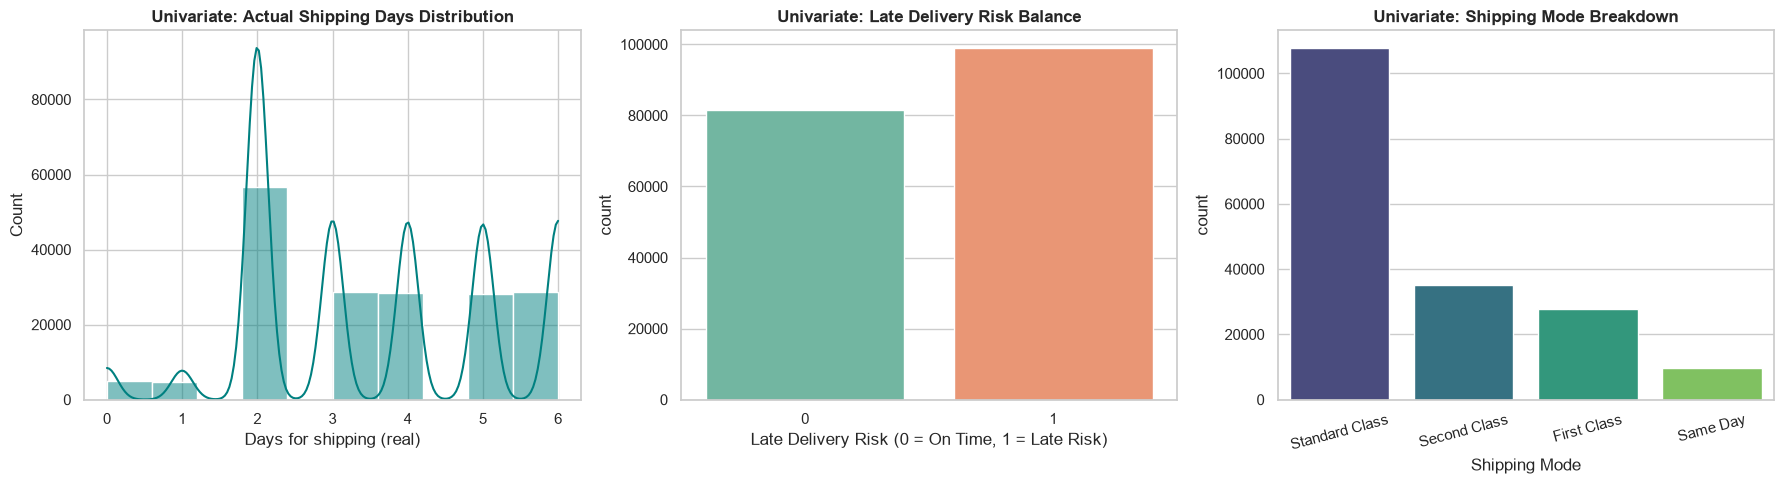

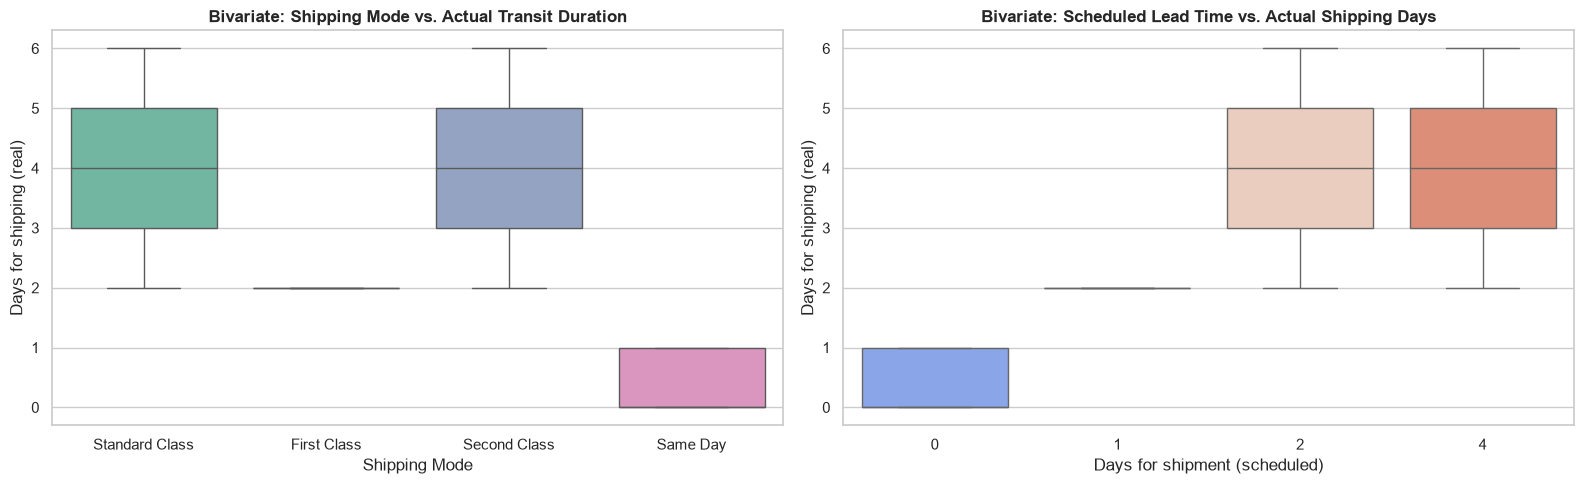

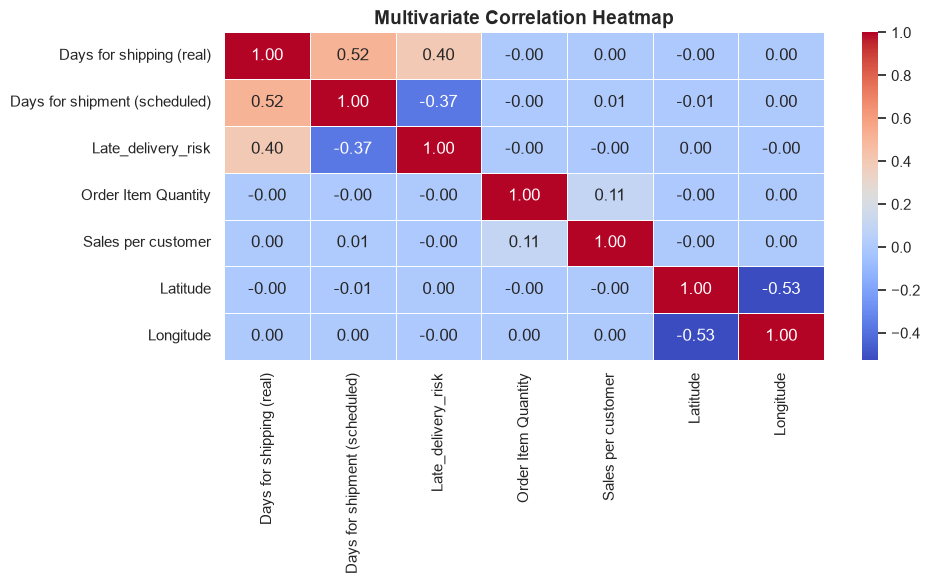

In [6]:
# STEP 4: EXPLORATORY DATA ANALYSIS (EDA)
# 4.1 Univariate Distribution Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Regression Target Distribution
sns.histplot(df['Days for shipping (real)'], kde=True, ax=axes[0], color='teal', bins=10)
axes[0].set_title('Univariate: Actual Shipping Days Distribution', fontweight='bold')
axes[0].set_xlabel('Days for shipping (real)')

# Plot 2: Classification Target Distribution
sns.countplot(x='Late_delivery_risk', data=df, ax=axes[1], palette='Set2')
axes[1].set_title('Univariate: Late Delivery Risk Balance', fontweight='bold')
axes[1].set_xlabel('Late Delivery Risk (0 = On Time, 1 = Late Risk)')

# Plot 3: Shipping Mode Distribution
sns.countplot(x='Shipping Mode', data=df, ax=axes[2], palette='viridis', order=df['Shipping Mode'].value_counts().index)
axes[2].set_title('Univariate: Shipping Mode Breakdown', fontweight='bold')
axes[2].set_xlabel('Shipping Mode')
axes[2].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# 4.2 Bivariate & Multivariate Analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(x='Shipping Mode', y='Days for shipping (real)', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Bivariate: Shipping Mode vs. Actual Transit Duration', fontweight='bold')

sns.boxplot(x='Days for shipment (scheduled)', y='Days for shipping (real)', data=df, ax=axes[1], palette='coolwarm')
axes[1].set_title('Bivariate: Scheduled Lead Time vs. Actual Shipping Days', fontweight='bold')

plt.tight_layout()
plt.show()

# Multivariate Correlation Heatmap
plt.figure(figsize=(10, 6))
heatmap_cols = ['Days for shipping (real)', 'Days for shipment (scheduled)', 'Late_delivery_risk', 'Order Item Quantity', 'Sales per customer', 'Latitude', 'Longitude']
heatmap_cols = [c for c in heatmap_cols if c in df.columns]
sns.heatmap(df[heatmap_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Multivariate Correlation Heatmap', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()


In [5]:
# STEP 5: ENHANCED DATA CLEANING & FEATURE ENGINEERING
reg_target_col = 'Days for shipping (real)'
cls_target_col = 'Late_delivery_risk'

base_num_cols = ['Days for shipment (scheduled)', 'Order Item Quantity', 'Sales per customer', 'Latitude', 'Longitude']
cat_cols = ['Shipping Mode', 'Market', 'Order Region']
date_col = 'order date (DateOrders)'

base_num_cols = [c for c in base_num_cols if c in df.columns]
cat_cols = [c for c in cat_cols if c in df.columns]

df_proc = df[base_num_cols + cat_cols + [date_col, reg_target_col, cls_target_col]].copy()

# 1. Missing Value Imputation
for col in base_num_cols + [reg_target_col, cls_target_col]:
    if df_proc[col].isnull().sum() > 0:
        df_proc[col] = df_proc[col].fillna(df_proc[col].mean())

for col in cat_cols:
    if df_proc[col].isnull().sum() > 0:
        df_proc[col] = df_proc[col].fillna('Unknown')

# 2. Advanced Domain Feature Engineering
print("-> Engineering Domain Interaction Features & Spatial Proxies...")

# A. Spatial Distance Proxy
if 'Latitude' in df_proc.columns and 'Longitude' in df_proc.columns:
    df_proc['Spatial_Distance_Proxy'] = np.sqrt(df_proc['Latitude']**2 + df_proc['Longitude']**2)
else:
    df_proc['Spatial_Distance_Proxy'] = 0.0

# B. Sales-per-Item Ratio
if 'Sales per customer' in df_proc.columns and 'Order Item Quantity' in df_proc.columns:
    df_proc['Sales_Per_Item_Ratio'] = df_proc['Sales per customer'] / (df_proc['Order Item Quantity'] + 1e-5)
else:
    df_proc['Sales_Per_Item_Ratio'] = 0.0

engineered_num_cols = ['Spatial_Distance_Proxy', 'Sales_Per_Item_Ratio']

# 3. Cyclical Temporal Transformations
print("-> Transforming Dates to 2D Cyclical Sine/Cosine Features...")
df_proc[date_col] = pd.to_datetime(df_proc[date_col], errors='coerce')
month = df_proc[date_col].dt.month.fillna(1)
dayofweek = df_proc[date_col].dt.dayofweek.fillna(0)

df_proc['Month_sin'] = np.sin(2 * np.pi * month / 12.0)
df_proc['Month_cos'] = np.cos(2 * np.pi * month / 12.0)
df_proc['DayOfWeek_sin'] = np.sin(2 * np.pi * dayofweek / 7.0)
df_proc['DayOfWeek_cos'] = np.cos(2 * np.pi * dayofweek / 7.0)

cyclical_cols = ['Month_sin', 'Month_cos', 'DayOfWeek_sin', 'DayOfWeek_cos']

# 4. Label Encoding Categoricals
encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df_proc[col] = le.fit_transform(df_proc[col].astype(str))
    encoders[col] = le

# 5. Min-Max Normalization
scaler = MinMaxScaler()
all_numerical = base_num_cols + engineered_num_cols + cyclical_cols
df_proc[all_numerical] = scaler.fit_transform(df_proc[all_numerical])

# 6. Predictor Matrix & Partitioning
X_cols = base_num_cols + engineered_num_cols + cyclical_cols + cat_cols
X = df_proc[X_cols]
y_reg = df_proc[reg_target_col]
y_cls = df_proc[cls_target_col]

X_train, X_test, y_train_reg, y_test_reg, y_train_cls, y_test_cls = train_test_split(
    X, y_reg, y_cls, test_size=0.20, random_state=42
)

print("Preprocessing & Feature Engineering Complete!")
print(f"Predictors Matrix X: {X.shape} | Training set: {X_train.shape} | Test set: {X_test.shape}")


-> Engineering Domain Interaction Features & Spatial Proxies...
-> Transforming Dates to 2D Cyclical Sine/Cosine Features...
Preprocessing & Feature Engineering Complete!
Predictors Matrix X: (180519, 14) | Training set: (144415, 14) | Test set: (36104, 14)


In [13]:
# STEP 6: TASK 1 - REGRESSION MODELING & HYPERPARAMETER TUNING
print("--- 1. Baseline Linear Regression ---")
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train_reg)

print("--- 2. Tuning Random Forest Regressor (RandomizedSearchCV) ---")
param_rf_reg = {
    'n_estimators': [50, 100, 150],
    'max_depth': [8, 12, 16, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
rf_reg_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_rf_reg,
    n_iter=6,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)
rf_reg_search.fit(X_train, y_train_reg)
best_rf_reg = rf_reg_search.best_estimator_
print(f"  Best RF Regressor Params: {rf_reg_search.best_params_}")

print("--- 3. Tuning XGBoost Regressor (RandomizedSearchCV) ---")
param_xgb_reg = {
    'n_estimators': [100, 200],
    'max_depth': [4, 6, 8, 10],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9],
    'reg_alpha': [0, 0.1, 1],
    'reg_lambda': [1, 5, 10]
}
xgb_reg_search = RandomizedSearchCV(
    xgb.XGBRegressor(objective='reg:squarederror', random_state=42, n_jobs=-1),
    param_distributions=param_xgb_reg,
    n_iter=8,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)
xgb_reg_search.fit(X_train, y_train_reg)
best_xgb_reg = xgb_reg_search.best_estimator_
print(f"  Best XGBoost Regressor Params: {xgb_reg_search.best_params_}")

# Regression Benchmarking
reg_candidates = {
    'Linear Regression (Baseline)': lr_reg,
    'Tuned Random Forest Regressor': best_rf_reg,
    'Tuned XGBoost Regressor': best_xgb_reg
}

reg_summary = []
for name, model in reg_candidates.items():
    # Train set evaluation (80%)
    y_train_pred = model.predict(X_train)
    r2_train = r2_score(y_train_reg, y_train_pred)
    mae_train = mean_absolute_error(y_train_reg, y_train_pred)
    rmse_train = np.sqrt(mean_squared_error(y_train_reg, y_train_pred))

    # Test set evaluation (20%)
    y_test_pred = model.predict(X_test)
    r2_test = r2_score(y_test_reg, y_test_pred)
    mae_test = mean_absolute_error(y_test_reg, y_test_pred)
    rmse_test = np.sqrt(mean_squared_error(y_test_reg, y_test_pred))

    reg_summary.append({
        'Model': name,
        'Train R2': r2_train,
        'Test R2': r2_test,
        'Train MAE': mae_train,
        'Test MAE': mae_test,
        'Train RMSE': rmse_train,
        'Test RMSE': rmse_test
    })

df_reg_summary = pd.DataFrame(reg_summary).sort_values(by='Test R2', ascending=False)
print("\n================ REGRESSION PERFORMANCE SUMMARY (TRAIN 80% vs TEST 20%) ================")
print(df_reg_summary.to_string(index=False))


--- 1. Baseline Linear Regression ---
--- 2. Tuning Random Forest Regressor (RandomizedSearchCV) ---
  Best RF Regressor Params: {'n_estimators': 150, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': None}
--- 3. Tuning XGBoost Regressor (RandomizedSearchCV) ---
  Best XGBoost Regressor Params: {'subsample': 0.8, 'reg_lambda': 10, 'reg_alpha': 1, 'n_estimators': 200, 'max_depth': 10, 'learning_rate': 0.1, 'colsample_bytree': 0.8}

================ REGRESSION PERFORMANCE SUMMARY (TRAIN 80% vs TEST 20%) ================
                        Model  Train R2  Test R2  Train MAE  Test MAE  Train RMSE  Test RMSE
Tuned Random Forest Regressor  0.954134 0.668433   0.256437  0.694900    0.347747   0.934883
      Tuned XGBoost Regressor  0.627285 0.487496   0.777242  0.918161    0.991308   1.162307
 Linear Regression (Baseline)  0.276572 0.280088   1.091626  1.088652    1.381076   1.377564


--- 1. Baseline Logistic Regression ---
--- 2. Tuning Random Forest Classifier ---
--- 3. Tuning XGBoost Classifier ---

================ CLASSIFICATION PERFORMANCE SUMMARY (TRAIN 80% vs TEST 20%, Threshold = 0.5) ================
                         Model  Train Acc  Test Acc  Train Prec  Test Prec  Train Rec  Test Rec  Train F1  Test F1
Tuned Random Forest Classifier   0.743662  0.710725    0.871915   0.844951   0.624160  0.578623  0.727523 0.686874
Logistic Regression (Baseline)   0.691549  0.687542    0.797107   0.793009   0.586777  0.582108  0.675959 0.671386
      Tuned XGBoost Classifier   0.708839  0.698704    0.850302   0.838842   0.569159  0.557660  0.681888 0.669944

-> Optimizing Decision Cutoff Threshold for 'Tuned Random Forest Classifier'...
Optimal Classification Threshold Found: 0.39
Enhanced F1-Score at Threshold 0.39: 0.7663


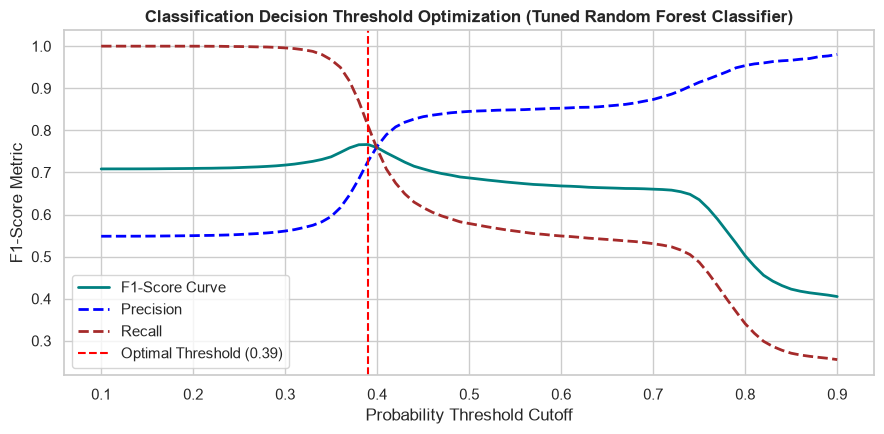

In [18]:
# STEP 7: TASK 2 - CLASSIFICATION MODELING & THRESHOLD OPTIMIZATION
print("--- 1. Baseline Logistic Regression ---")
log_cls = LogisticRegression(max_iter=1000, random_state=42)
log_cls.fit(X_train, y_train_cls)

print("--- 2. Tuning Random Forest Classifier ---")
param_rf_cls = {
    'n_estimators': [50, 100, 150],
    'max_depth': [8, 12, 16],
    'min_samples_split': [2, 5, 10],
    'class_weight': ['balanced', None]
}
rf_cls_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_rf_cls,
    n_iter=6,
    cv=3,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)
rf_cls_search.fit(X_train, y_train_cls)
best_rf_cls = rf_cls_search.best_estimator_

print("--- 3. Tuning XGBoost Classifier ---")
scale_pos_weight_val = (len(y_train_cls) - sum(y_train_cls)) / max(sum(y_train_cls), 1)

param_xgb_cls = {
    'n_estimators': [100, 200],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9],
    'scale_pos_weight': [1.0, scale_pos_weight_val]
}
xgb_cls_search = RandomizedSearchCV(
    xgb.XGBClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_xgb_cls,
    n_iter=8,
    cv=3,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)
xgb_cls_search.fit(X_train, y_train_cls)
best_xgb_cls = xgb_cls_search.best_estimator_

# Classification Benchmarking (Standard Threshold = 0.5)
cls_candidates = {
    'Logistic Regression (Baseline)': log_cls,
    'Tuned Random Forest Classifier': best_rf_cls,
    'Tuned XGBoost Classifier': best_xgb_cls
}

cls_summary = []
for name, model in cls_candidates.items():
    # Train set evaluation (80%)
    y_train_pred = model.predict(X_train)
    acc_train = accuracy_score(y_train_cls, y_train_pred)
    prec_train = precision_score(y_train_cls, y_train_pred, zero_division=0)
    rec_train = recall_score(y_train_cls, y_train_pred, zero_division=0)
    f1_train = f1_score(y_train_cls, y_train_pred, zero_division=0)

    # Test set evaluation (20%)
    y_test_pred = model.predict(X_test)
    acc_test = accuracy_score(y_test_cls, y_test_pred)
    prec_test = precision_score(y_test_cls, y_test_pred, zero_division=0)
    rec_test = recall_score(y_test_cls, y_test_pred, zero_division=0)
    f1_test = f1_score(y_test_cls, y_test_pred, zero_division=0)

    cls_summary.append({
        'Model': name,
        'Train Acc': acc_train,
        'Test Acc': acc_test,
        'Train Prec': prec_train,
        'Test Prec': prec_test,
        'Train Rec': rec_train,
        'Test Rec': rec_test,
        'Train F1': f1_train,
        'Test F1': f1_test
    })

df_cls_summary = pd.DataFrame(cls_summary).sort_values(by='Test F1', ascending=False)
print("\n================ CLASSIFICATION PERFORMANCE SUMMARY (TRAIN 80% vs TEST 20%, Threshold = 0.5) ================")
print(df_cls_summary.to_string(index=False))

# --- DECISION THRESHOLD OPTIMIZATION FOR WINNING CLASSIFIER ---
best_cls_name = df_cls_summary.iloc[0]['Model']
best_cls_model = cls_candidates[best_cls_name]

print(f"\n-> Optimizing Decision Cutoff Threshold for '{best_cls_name}'...")
y_probs = best_cls_model.predict_proba(X_test)[:, 1]

thresholds = np.linspace(0.1, 0.9, 81)
threshold_scores = []

for th in thresholds:
    y_pred_th = (y_probs >= th).astype(int)
    f1_th = f1_score(y_test_cls, y_pred_th, zero_division=0)
    acc_th = accuracy_score(y_test_cls, y_pred_th)
    pre_th = precision_score(y_test_cls, y_pred_th, zero_division=0)
    rec_th = recall_score(y_test_cls, y_pred_th, zero_division=0)
    threshold_scores.append({'Threshold': th, 'F1-Score': f1_th, 'Accuracy': acc_th, 'Precision': pre_th, 'Recall':rec_th})

df_th = pd.DataFrame(threshold_scores)
best_th_row = df_th.loc[df_th['F1-Score'].idxmax()]
optimal_threshold = best_th_row['Threshold']

print(f"Optimal Classification Threshold Found: {optimal_threshold:.2f}")
print(f"Enhanced F1-Score at Threshold {optimal_threshold:.2f}: {best_th_row['F1-Score']:.4f}")

# Plot Decision Threshold Optimization Curve
plt.figure(figsize=(9, 4.5))
plt.plot(df_th['Threshold'], df_th['F1-Score'], label='F1-Score Curve', color='teal', linewidth=2)
plt.plot(df_th['Threshold'], df_th['Precision'], label='Precision', color='blue',linestyle='--', linewidth=2)
plt.plot(df_th['Threshold'], df_th['Recall'], label='Recall', color='brown',linestyle='--', linewidth=2)
plt.axvline(optimal_threshold, color='red', linestyle='--', label=f'Optimal Threshold ({optimal_threshold:.2f})')
plt.title(f'Classification Decision Threshold Optimization ({best_cls_name})', fontweight='bold')
plt.xlabel('Probability Threshold Cutoff')
plt.ylabel('F1-Score Metric')
plt.legend()
plt.tight_layout()
plt.show()


In [16]:
# STEP 8: OPERATIONAL DUAL-TARGET INFERENCE & LATE RISK FLAGGING
best_reg_name = df_reg_summary.iloc[0]['Model']
best_reg_model = reg_candidates[best_reg_name]

print(f"Using Winning Regressor: {best_reg_name}")
print(f"Using Winning Classifier: {best_cls_name} (Threshold = {optimal_threshold:.2f})")

# Sample 5 shipments from test set
sample_indices = X_test.index[:5]
sample_X = X_test.iloc[:5]

pred_shipping_days = best_reg_model.predict(sample_X)
pred_risk_probs = best_cls_model.predict_proba(sample_X)[:, 1]
pred_risk_flags = (pred_risk_probs >= optimal_threshold).astype(int)

scheduled_days = df['Days for shipment (scheduled)'].iloc[sample_indices].values
actual_days = y_test_reg.iloc[:5].values
actual_risk = y_test_cls.iloc[:5].values

# Build Operational Decision DataFrame
inference_df = pd.DataFrame({
    'Scheduled Days': scheduled_days,
    'Actual Shipping Days': actual_days,
    'Predicted Shipping Days': np.round(pred_shipping_days, 2),
    'Actual Risk Flag': actual_risk,
    'Late Risk Probability': np.round(pred_risk_probs, 4),
    'Predicted Risk Flag': pred_risk_flags,
    'Operational Status': ["⚠️ LATE RISK" if r == 1 else "✅ ON TIME" for r in pred_risk_flags]
})

print("\n================ DUAL-TARGET PREDICTION INFERENCE SAMPLE ================")
print(inference_df.to_string(index=False))


Using Winning Regressor: Tuned Random Forest Regressor
Using Winning Classifier: Tuned Random Forest Classifier (Threshold = 0.39)

================ DUAL-TARGET PREDICTION INFERENCE SAMPLE ================
 Scheduled Days  Actual Shipping Days  Predicted Shipping Days  Actual Risk Flag  Late Risk Probability  Predicted Risk Flag Operational Status
              4                     5                     4.76                 1                 0.4690                    1       ⚠️ LATE RISK
              1                     2                     2.00                 1                 0.9760                    1       ⚠️ LATE RISK
              4                     2                     3.75                 0                 0.3531                    0          ✅ ON TIME
              4                     5                     4.38                 1                 0.4309                    1       ⚠️ LATE RISK
              4                     2                     2.99            

STEP 9: STATISTICAL SIGNIFICANCE TESTS OF THE MODEL PREDICTIONS
1. H0 (null hypothesis) = "nothing special is happening" (e.g. the model is no better than guessing).
2. H1 (alternative hypothesis) = "the model really does something useful".
3. The test gives a p-value: the chance of seeing results at least this good if H0 were true.
4. Decision rule:** if p < 0.05 we reject H0 (the result is statistically significant). If p ≥ 0.05 we fail to reject H0 (not enough evidence).

In [9]:
# STEP 9A: STATISTICAL TESTS FOR THE REGRESSION MODELS
from scipy import stats

ALPHA = 0.05          # significance level: reject H0 when p-value < 0.05
test_results = []     # every test is stored here and summarised in Step 9C

def p_text(p):
    return "< 1e-300" if p < 1e-300 else f"{p:.2e}"

def decide(p):
    return "REJECT H0" if p < ALPHA else "FAIL TO REJECT H0"

y_true = np.asarray(y_test_reg)
reg_names = list(reg_candidates.keys())          # [baseline, Random Forest, XGBoost]
baseline_reg = reg_names[0]
reg_preds = {name: model.predict(X_test) for name, model in reg_candidates.items()}

# ---------- TEST 1: Pearson correlation between predicted and actual days ----------
print("TEST 1 - Pearson correlation (H0: no relationship between predicted and actual days)")
for name, pred in reg_preds.items():
    r, p = stats.pearsonr(y_true, pred)
    strength = "weak" if abs(r) < 0.3 else ("moderate" if abs(r) < 0.5 else "strong")
    test_results.append({
        'Task': 'Regression', 'Test': 'Pearson correlation', 'Model': name,
        'Statistic': f"r = {r:.4f}", 'p-value': p, 'Decision': decide(p),
        'Effect size': f"r = {r:.3f} ({strength})",
        'If rejected': "Predictions are significantly related to actual shipping days.",
        'If not rejected': "No evidence that predictions are related to actual shipping days."})
    print(f"  {name:<32} r = {r:.4f} | p = {p_text(p)} | {decide(p)}")

# ---------- TEST 2: paired t-test of absolute errors, each tuned model vs the baseline ----------
print("\nTEST 2 - Paired t-test (H0: model error is NOT smaller than the baseline's error)")
abs_err = {name: np.abs(y_true - pred) for name, pred in reg_preds.items()}

for name in reg_names[1:]:
    t, p = stats.ttest_rel(abs_err[baseline_reg], abs_err[name], alternative='greater')
    diff = abs_err[baseline_reg] - abs_err[name]          # positive = the model is better
    mean_diff = diff.mean()
    se = diff.std(ddof=1) / np.sqrt(len(diff))
    test_results.append({
        'Task': 'Regression', 'Test': 'Paired t-test vs baseline', 'Model': name,
        'Statistic': f"t = {t:.2f}", 'p-value': p, 'Decision': decide(p),
        'Effect size': f"baseline error minus model error = {mean_diff:+.3f} days (positive = model better; 95% CI {mean_diff-1.96*se:+.3f} to {mean_diff+1.96*se:+.3f})",
        'If rejected': "The model makes significantly smaller errors than the baseline.",
        'If not rejected': "No evidence that the model is more accurate than the baseline."})
    print(f"  {name:<32} t = {t:.2f} | p = {p_text(p)} | {decide(p)} | baseline error minus model error = {mean_diff:+.3f} days")

# ---------- TEST 3: Random Forest vs XGBoost (two-sided) ----------
print("\nTEST 3 - Paired t-test between the two tuned models (H0: same average error)")
a, b = reg_names[1], reg_names[2]
t, p = stats.ttest_rel(abs_err[a], abs_err[b], alternative='two-sided')
diff = abs_err[a] - abs_err[b]
mean_diff = diff.mean()
se = diff.std(ddof=1) / np.sqrt(len(diff))
better = b if mean_diff > 0 else a
test_results.append({
    'Task': 'Regression', 'Test': 'Paired t-test (RF vs XGBoost)', 'Model': f"{a} vs {b}",
    'Statistic': f"t = {t:.2f}", 'p-value': p, 'Decision': decide(p),
    'Effect size': f"{abs(mean_diff):.3f} days difference in favour of {better}",
    'If rejected': f"The two models differ significantly; {better} has the smaller error.",
    'If not rejected': "The two models are statistically equally accurate; the leaderboard order may be chance."})
print(f"  {a} vs {b}: t = {t:.2f} | p = {p_text(p)} | {decide(p)} | {better} has the smaller error by {abs(mean_diff):.3f} days")

TEST 1 - Pearson correlation (H0: no relationship between predicted and actual days)
  Linear Regression (Baseline)     r = 0.5292 | p = < 1e-300 | REJECT H0
  Tuned Random Forest Regressor    r = 0.8252 | p = < 1e-300 | REJECT H0
  Tuned XGBoost Regressor          r = 0.6995 | p = < 1e-300 | REJECT H0

TEST 2 - Paired t-test (H0: model error is NOT smaller than the baseline's error)
  Tuned Random Forest Regressor    t = 118.74 | p = < 1e-300 | REJECT H0 | baseline error minus model error = +0.394 days
  Tuned XGBoost Regressor          t = 58.40 | p = < 1e-300 | REJECT H0 | baseline error minus model error = +0.170 days

TEST 3 - Paired t-test between the two tuned models (H0: same average error)
  Tuned Random Forest Regressor vs Tuned XGBoost Regressor: t = -123.98 | p = < 1e-300 | REJECT H0 | Tuned Random Forest Regressor has the smaller error by 0.223 days


In [10]:
# STEP 9B: STATISTICAL TESTS FOR THE CLASSIFICATION MODELS
y_c = np.asarray(y_test_cls).astype(int)
n_test = len(y_c)
cls_names = list(cls_candidates.keys())            # [baseline, Random Forest, XGBoost]
baseline_cls = cls_names[0]
cls_preds = {name: np.asarray(model.predict(X_test)).astype(int) for name, model in cls_candidates.items()}

majority_share = max(y_c.mean(), 1 - y_c.mean())   # accuracy of "always guess the most common class"
print(f"Accuracy of the 'always guess the most common class' strategy: {majority_share:.4f}\n")

# ---------- TEST 4: Chi-square test of independence (predicted vs actual) ----------
print("TEST 4 - Chi-square test (H0: predicted class is independent of the actual class)")
for name, pred in cls_preds.items():
    table = confusion_matrix(y_c, pred, labels=[0, 1])
    try:
        chi2, p, dof, expected = stats.chi2_contingency(table)
        phi = np.sqrt(chi2 / n_test)                  # effect size: 0 = no link, 1 = perfect link
    except ValueError:                                # happens if a model predicts only one class
        chi2, p, phi = 0.0, 1.0, 0.0
    strength = "weak" if phi < 0.3 else ("moderate" if phi < 0.5 else "strong")
    test_results.append({
        'Task': 'Classification', 'Test': 'Chi-square independence', 'Model': name,
        'Statistic': f"chi2 = {chi2:.1f}", 'p-value': p, 'Decision': decide(p),
        'Effect size': f"phi = {phi:.3f} ({strength})",
        'If rejected': "Predicted and actual late/on-time outcomes are significantly associated.",
        'If not rejected': "No evidence that the predictions are linked to the real outcomes."})
    print(f"  {name:<32} chi2 = {chi2:.1f} | p = {p_text(p)} | {decide(p)} | phi = {phi:.3f}")

# ---------- TEST 5: Binomial test - is accuracy better than always guessing the majority class? ----------
print("\nTEST 5 - Binomial test (H0: accuracy is no better than the majority-class guess)")
cls_acc_ci = {}
for name, pred in cls_preds.items():
    correct = int((pred == y_c).sum())
    res = stats.binomtest(correct, n_test, majority_share, alternative='greater')
    acc = correct / n_test
    ci = stats.binomtest(correct, n_test).proportion_ci(confidence_level=0.95)
    cls_acc_ci[name] = (acc, ci.low, ci.high)
    test_results.append({
        'Task': 'Classification', 'Test': 'Binomial test vs majority guess', 'Model': name,
        'Statistic': f"accuracy = {acc:.4f}", 'p-value': res.pvalue, 'Decision': decide(res.pvalue),
        'Effect size': f"{(acc - majority_share) * 100:+.2f} percentage points vs guessing (95% CI for accuracy {ci.low:.4f} to {ci.high:.4f})",
        'If rejected': "The model is significantly more accurate than always guessing the most common class.",
        'If not rejected': "The model is not shown to beat the simple majority-class guess."})
    print(f"  {name:<32} accuracy = {acc:.4f} | p = {p_text(res.pvalue)} | {decide(res.pvalue)} | {(acc - majority_share) * 100:+.2f} points vs guessing")

# ---------- TEST 6: McNemar test - is a tuned model correct more often than the baseline? ----------
print("\nTEST 6 - McNemar test (H0: both models make mistakes equally often)")
def mcnemar(pred_a, pred_b, alternative):
    a_ok = (pred_a == y_c); b_ok = (pred_b == y_c)
    only_a = int((a_ok & ~b_ok).sum())      # A right, B wrong
    only_b = int((~a_ok & b_ok).sum())      # A wrong, B right
    if only_a + only_b == 0:
        return only_a, only_b, 1.0
    return only_a, only_b, stats.binomtest(only_b, only_a + only_b, 0.5, alternative=alternative).pvalue

for name in cls_names[1:]:
    only_base, only_model, p = mcnemar(cls_preds[baseline_cls], cls_preds[name], 'greater')
    test_results.append({
        'Task': 'Classification', 'Test': 'McNemar vs baseline', 'Model': name,
        'Statistic': f"{only_model} vs {only_base} disagreements", 'p-value': p, 'Decision': decide(p),
        'Effect size': f"model right / baseline wrong = {only_model}; baseline right / model wrong = {only_base}",
        'If rejected': "The model is correct significantly more often than the baseline.",
        'If not rejected': "No evidence that the model beats the baseline."})
    print(f"  {name:<32} model-only correct = {only_model} | baseline-only correct = {only_base} | p = {p_text(p)} | {decide(p)}")

a, b = cls_names[1], cls_names[2]
only_a, only_b, p = mcnemar(cls_preds[a], cls_preds[b], 'two-sided')
test_results.append({
    'Task': 'Classification', 'Test': 'McNemar (RF vs XGBoost)', 'Model': f"{a} vs {b}",
    'Statistic': f"{only_b} vs {only_a} disagreements", 'p-value': p, 'Decision': decide(p),
    'Effect size': f"{b} only correct = {only_b}; {a} only correct = {only_a}",
    'If rejected': "One of the two tuned models is significantly better than the other.",
    'If not rejected': "The two tuned models are statistically equally accurate."})
print(f"  {a} vs {b}: only-RF correct = {only_a} | only-XGB correct = {only_b} | p = {p_text(p)} | {decide(p)}")

Accuracy of the 'always guess the most common class' strategy: 0.5483

TEST 4 - Chi-square test (H0: predicted class is independent of the actual class)
  Logistic Regression (Baseline)   chi2 = 5877.4 | p = < 1e-300 | REJECT H0 | phi = 0.403
  Tuned Random Forest Classifier   chi2 = 7710.0 | p = < 1e-300 | REJECT H0 | phi = 0.462
  Tuned XGBoost Classifier         chi2 = 7055.7 | p = < 1e-300 | REJECT H0 | phi = 0.442

TEST 5 - Binomial test (H0: accuracy is no better than the majority-class guess)
  Logistic Regression (Baseline)   accuracy = 0.6875 | p = < 1e-300 | REJECT H0 | +13.92 points vs guessing
  Tuned Random Forest Classifier   accuracy = 0.7107 | p = < 1e-300 | REJECT H0 | +16.24 points vs guessing
  Tuned XGBoost Classifier         accuracy = 0.6987 | p = < 1e-300 | REJECT H0 | +15.04 points vs guessing

TEST 6 - McNemar test (H0: both models make mistakes equally often)
  Tuned Random Forest Classifier   model-only correct = 1229 | baseline-only correct = 392 | p = 9.81e

================ STATISTICAL TEST SUMMARY (alpha = 0.05) ================
          Task                            Test                                                      Model                 Statistic p-value (text)  Decision
    Regression             Pearson correlation                               Linear Regression (Baseline)                r = 0.5292       < 1e-300 REJECT H0
    Regression             Pearson correlation                              Tuned Random Forest Regressor                r = 0.8252       < 1e-300 REJECT H0
    Regression             Pearson correlation                                    Tuned XGBoost Regressor                r = 0.6995       < 1e-300 REJECT H0
    Regression       Paired t-test vs baseline                              Tuned Random Forest Regressor                t = 118.74       < 1e-300 REJECT H0
    Regression       Paired t-test vs baseline                                    Tuned XGBoost Regressor                 t = 58.40       < 1

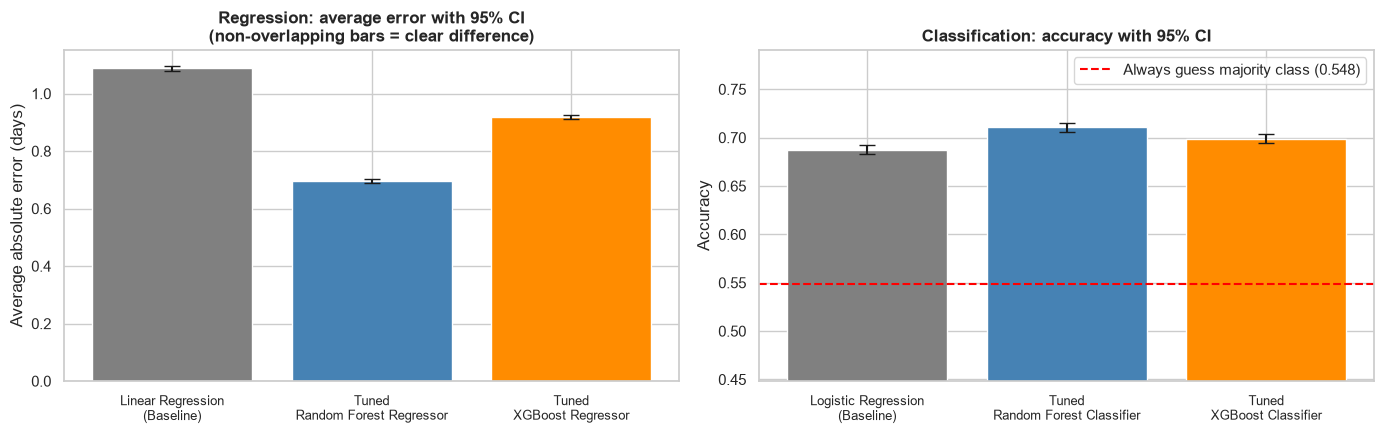


================ CRITICAL ANALYSIS OF THE TEST RESULTS ================
15 of 15 null hypotheses were rejected at the 5% level.

[Regression] Pearson correlation - Linear Regression (Baseline)
    p = < 1e-300 -> REJECT H0
    Effect size: r = 0.529 (strong)
    Meaning: Predictions are significantly related to actual shipping days.

[Regression] Pearson correlation - Tuned Random Forest Regressor
    p = < 1e-300 -> REJECT H0
    Effect size: r = 0.825 (strong)
    Meaning: Predictions are significantly related to actual shipping days.

[Regression] Pearson correlation - Tuned XGBoost Regressor
    p = < 1e-300 -> REJECT H0
    Effect size: r = 0.700 (strong)
    Meaning: Predictions are significantly related to actual shipping days.

[Regression] Paired t-test vs baseline - Tuned Random Forest Regressor
    p = < 1e-300 -> REJECT H0
    Effect size: baseline error minus model error = +0.394 days (positive = model better; 95% CI +0.387 to +0.400)
    Meaning: The model makes signific

In [17]:
# STEP 9C: SUMMARY TABLE, CHARTS AND CRITICAL ANALYSIS
summary = pd.DataFrame(test_results)
summary['p-value (text)'] = summary['p-value'].apply(p_text)

print("================ STATISTICAL TEST SUMMARY (alpha = 0.05) ================")
print(summary[['Task', 'Test', 'Model', 'Statistic', 'p-value (text)', 'Decision']].to_string(index=False))

# ---- Chart 1: average absolute error with 95% confidence interval (regression) ----
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
means = [abs_err[n].mean() for n in reg_names]
cis = [1.96 * abs_err[n].std(ddof=1) / np.sqrt(len(abs_err[n])) for n in reg_names]
axes[0].bar(range(len(reg_names)), means, yerr=cis, capsize=6, color=['gray', 'steelblue', 'darkorange'])
axes[0].set_xticks(range(len(reg_names)))
axes[0].set_xticklabels([n.replace(' (Baseline)', '\n(Baseline)').replace('Tuned ', 'Tuned\n') for n in reg_names], fontsize=9)
axes[0].set_ylabel('Average absolute error (days)')
axes[0].set_title('Regression: average error with 95% CI\n(non-overlapping bars = clear difference)', fontweight='bold')

# ---- Chart 2: accuracy with 95% confidence interval vs majority-class guess (classification) ----
accs = [cls_acc_ci[n][0] for n in cls_names]
errs = [[cls_acc_ci[n][0] - cls_acc_ci[n][1] for n in cls_names], [cls_acc_ci[n][2] - cls_acc_ci[n][0] for n in cls_names]]
axes[1].bar(range(len(cls_names)), accs, yerr=errs, capsize=6, color=['gray', 'steelblue', 'darkorange'])
axes[1].axhline(majority_share, color='red', linestyle='--', label=f'Always guess majority class ({majority_share:.3f})')
axes[1].set_xticks(range(len(cls_names)))
axes[1].set_xticklabels([n.replace(' (Baseline)', '\n(Baseline)').replace('Tuned ', 'Tuned\n') for n in cls_names], fontsize=9)
axes[1].set_ylim(max(0, min(accs + [majority_share]) - 0.1), min(1.0, max(accs + [majority_share]) + 0.08))
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Classification: accuracy with 95% CI', fontweight='bold')
axes[1].legend()
plt.tight_layout()
plt.show()

# ---- Critical analysis (written automatically from the results above) ----
print("\n================ CRITICAL ANALYSIS OF THE TEST RESULTS ================")
n_reject = int((summary['Decision'] == 'REJECT H0').sum())
print(f"{n_reject} of {len(summary)} null hypotheses were rejected at the 5% level.\n")

for _, row in summary.iterrows():
    meaning = row['If rejected'] if row['Decision'] == 'REJECT H0' else row['If not rejected']
    print(f"[{row['Task']}] {row['Test']} - {row['Model']}")
    print(f"    p = {row['p-value (text)']} -> {row['Decision']}")
    print(f"    Effect size: {row['Effect size']}")
    print(f"    Meaning: {meaning}\n")

print("---- Overall conclusions ----")
reg_ok = summary[(summary['Task'] == 'Regression') & (summary['Test'] == 'Pearson correlation')]
cls_ok = summary[(summary['Task'] == 'Classification') & (summary['Test'] == 'Binomial test vs majority guess')]
if (reg_ok['Decision'] == 'REJECT H0').all():
    print("* Regression: H0 is rejected for every model -> all regression predictions are significantly related to the real shipping days.")
else:
    bad = ', '.join(reg_ok.loc[reg_ok['Decision'] != 'REJECT H0', 'Model'])
    print(f"* Regression: H0 is NOT rejected for: {bad} -> these predictions are not shown to be useful.")
if (cls_ok['Decision'] == 'REJECT H0').all():
    print("* Classification: H0 is rejected for every model -> all classifiers beat the 'guess the majority class' strategy.")
else:
    bad = ', '.join(cls_ok.loc[cls_ok['Decision'] != 'REJECT H0', 'Model'])
    print(f"* Classification: H0 is NOT rejected for: {bad} -> these classifiers are not shown to beat simple guessing.")
